In [2]:
import numpy as np
import sys
import os

sys.path.append(os.path.abspath(".."))

from class_particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter
from simulations import system_simulation
from plot import plot_results

# PENDULO
Un péndulo (sin control) suele modelarse en espacio de estados como:

$$
x = 
\begin{bmatrix}
\theta \\
\omega
\end{bmatrix}
$$

con 
- $\theta$: ángulo
- $\omega$: velocidad angular

Ecuación continua:

$$
\dot{\theta} = \omega \\
\dot{\omega} = -\frac{g}{L}sin(\theta)
$$

### Discretización
Dado que se trabaja con el tiempo discreto, se necesita realizar una aproximación numérica. En este caso se ha tomado Euler.

La idea es aproximar las derivadas como:

$$
x´(t)\approx \frac{x_{n+1} - x_n}{\Delta t} 
$$

y despejando:

$$
x_{n+1} = x_n + \Delta t \;x´(t_n)
$$

Por lo tanto, tras la discretización, las ecuacciones del péndulo quedan:

$$
\theta_{n+1} = \theta_{n} + \Delta t\;w_n \\
w_{n+1} = w_n - \Delta t\; \frac{g}{L}\;sin(\theta_n)
$$

Depende mucho del valor de $\Delta_t$ y no conservar la energía provocando que el péndulo gane energía artificial (oscilaciones cada vez más grandes) o perder energía (amortiguamiento artificial).

### Observación

En este ejemplo se tiene el caso en el que solamente se mide el ángulo:

$$
y_t = \theta_t + v_t
$$

### Ecuación en espacio de estados

Finalmente, el modelo en espacio de estados tiene la siguiente forma

- Vector estado

$$
x_k = \begin{bmatrix}
\theta_k \\
\omega_k
\end{bmatrix}
$$

- Modelo dinámico 

$$
x_{k+1} = \begin{bmatrix}
\theta_k + \omega_k\; \Delta_t \\
\omega_k - \frac{g}{L}\;sin(\theta_k)\;\Delta_t
\end{bmatrix}
+ w_k
$$

- Modelo de medición

$$
y_k = \begin{bmatrix} 1 &0 \end{bmatrix} x_k + v_k
$$

con 

$$
w_k \sim \mathcal{N}(0, Q)\quad \quad v_k \sim \mathcal{N}(0, R)\\\\[2ex]

Q = \begin{bmatrix}

10^{-4} &0\\
0 &10^{-3}
\end{bmatrix}

\quad \quad

R = \begin{bmatrix} 10^{-2} \end{bmatrix}
$$

In [3]:
# Definición función de transición
g = 9.81
L = 1.0
dt = 0.01

def f(x):
    theta, omega = x

    omega_dot = -(g / L) * np.sin(theta)

    theta_next = theta + omega * dt
    omega_next = omega + omega_dot * dt

    theta_next = (theta_next + np.pi) % (2*np.pi) - np.pi

    return np.array([theta_next, omega_next])

In [4]:
# Definicion funcion de medicion

def h(x):
    theta, omega = x

    return np.array([theta])

In [5]:
# Definicion ruido

Q = np.diag([1e-4, 1e-3]) #ruido de proceso
R = np.array([1e-2]) #ruido de medicion

In [6]:
# Simulacion
T = 500
x0 = np.array([
    np.deg2rad(45), # 45 grados iniciales
    0.0             # sin velocidad inicial 
])

x_true, y_obs = system_simulation(f, h, Q, R, x0, T)

### Bootstrap Filter

- Con re-muestreo

In [7]:
pf = BootstrapParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

pf.initialize(mean=np.array([0.0, 0.0]), cov=np.diag([0.5, 0.5]))

In [8]:
est = pf.run_filter(y_obs, resample_threshold=500)

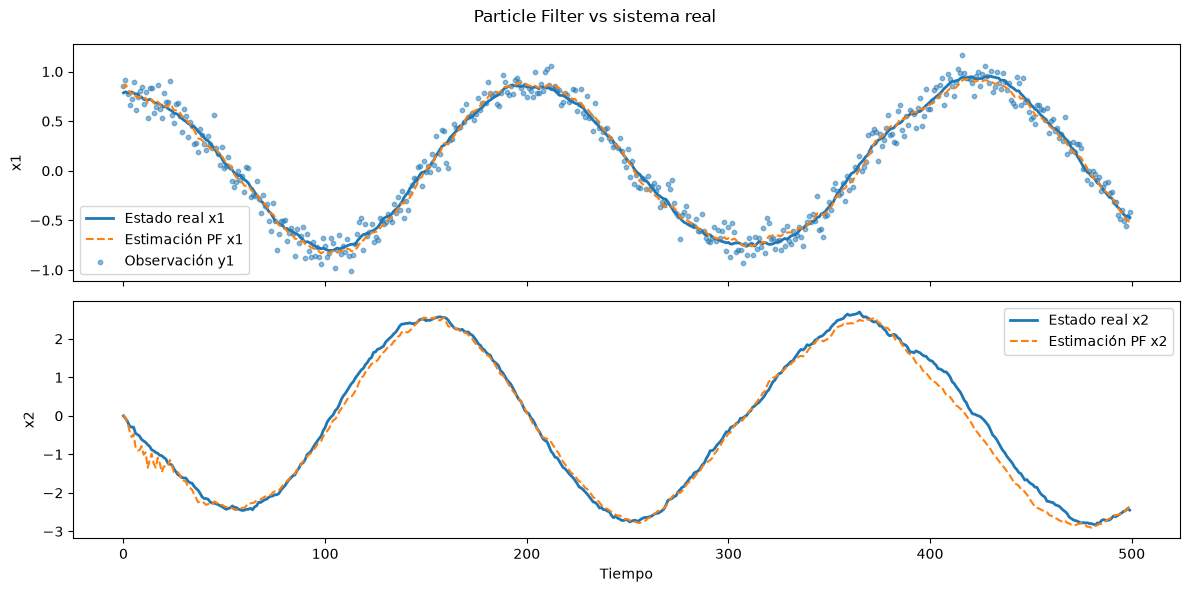

In [9]:
# --- Plot ---
x_est = est["estimates"]

plot_results(x_true, y_obs, x_est)

- Sin re-muestreo

In [10]:
bf = BootstrapParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

bf.initialize(mean=np.array([0.0, 0.0]), cov=np.diag([0.5, 0.5]))

In [11]:
est = bf.run_filter(y_obs)

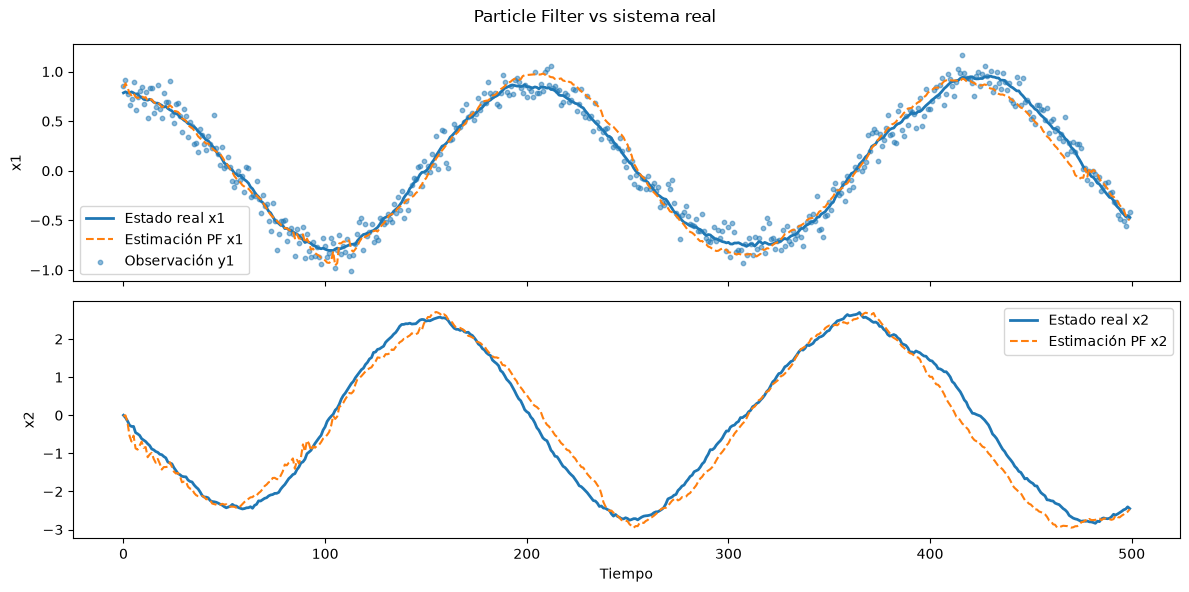

In [12]:
# --- Plot ---
x_est = est["estimates"]

plot_results(x_true, y_obs, x_est)

### Auxiliary Particle Filter

- Con re-muestreo

In [13]:
apf = AuxiliaryParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

apf.initialize(mean=np.array([0.0, 0.0]), cov=np.diag([0.5, 0.5]))

In [14]:
est = apf.run_filter(y_obs, resample_threshold=500)

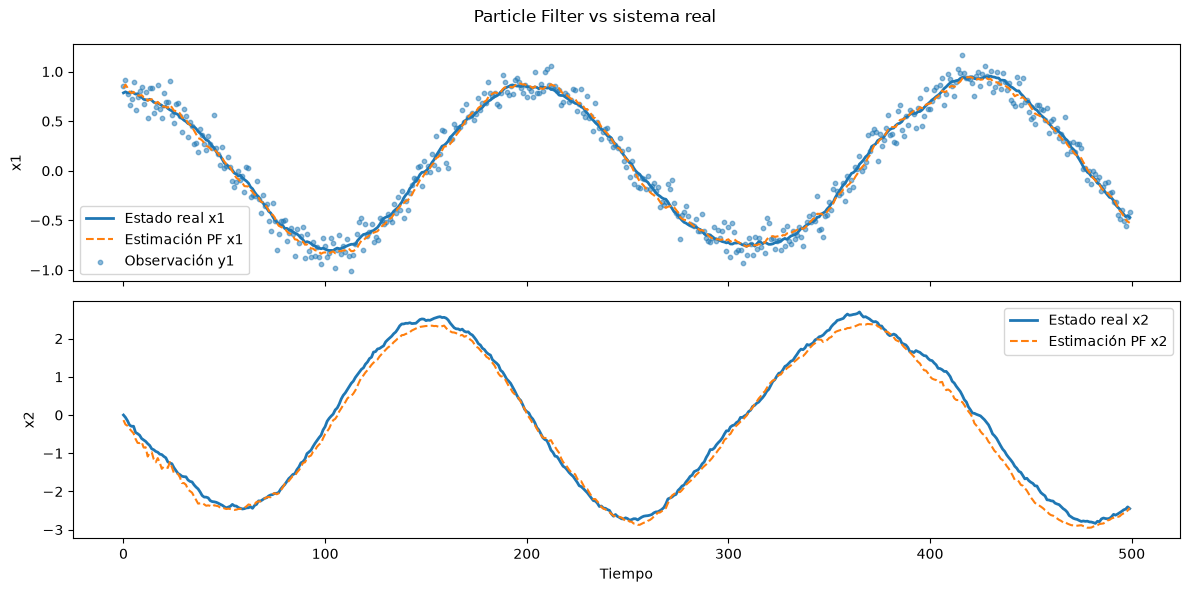

In [15]:
# --- Plot ---
x_est = est["estimates"]

plot_results(x_true, y_obs, x_est)

- Sin re-muestreo

In [16]:
apf = AuxiliaryParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

apf.initialize(mean=np.array([0.0, 0.0]), cov=np.diag([0.5, 0.5]))

In [17]:
est = apf.run_filter(y_obs)

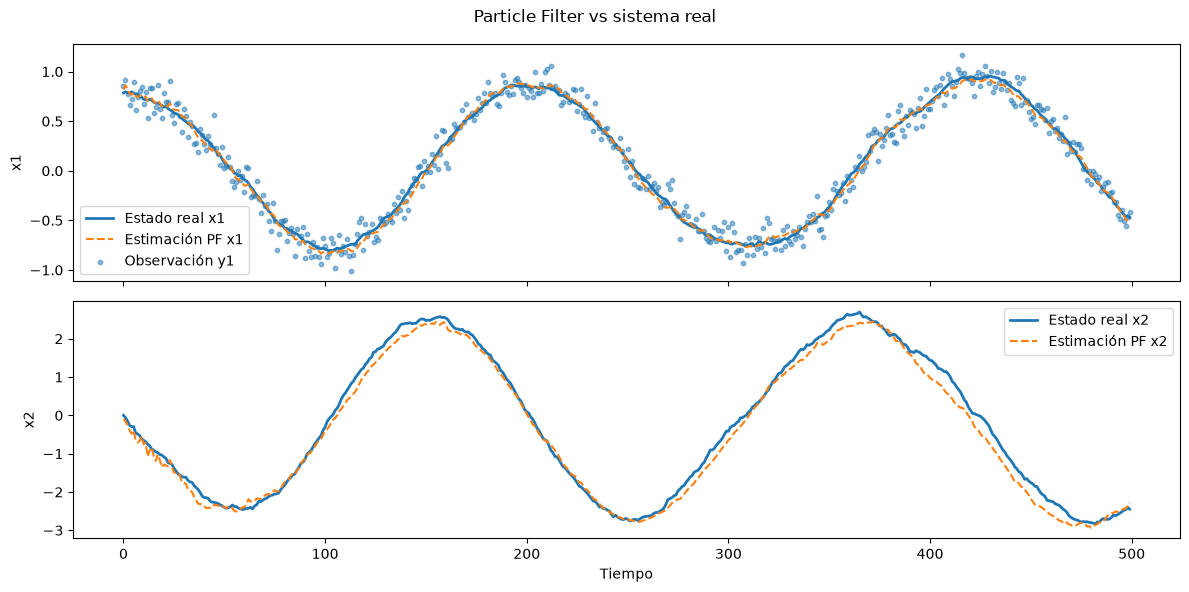

In [18]:
# --- Plot ---
x_est = est["estimates"]

plot_results(x_true, y_obs, x_est)